# Pirate Intelligent Agent
**Russell Chimunya | CS 370 Project Two**

This notebook completes the milestone using TensorFlow/Keras DQN. Supplied `TreasureMaze.py` and `GameExperience.py` are copied byte for byte, not edited. Run all cells in order. One outer epoch means one training game; a replay item is one transition, not an entire episode.

The final outputs distinguish training-window wins, all-start greedy completion, and top-left performance. A first verified stopping epoch is an observed result for one seed, not a globally optimal training budget or a guarantee of shortest paths.


<div class="alert alert-block alert-success" style="color:black;">
<b>To Begin:</b> Use this <b>TreasureHuntGame_starterCode.ipynb</b> file to complete your assignment. 
<br><br>
You have been provided with two Python classes and this notebook to help you with this assignment. The first class, <b>TreasureMaze.py</b>, represents the environment, which includes a maze object defined as a matrix. The second class, <b>GameExperience.py</b>, stores the episodes – that is, all the states that come in between the initial state and the terminal state. This is later used by the agent for learning by experience, called "exploration". This notebook shows how to play a game. Your task is to complete the deep Q-learning implementation in the qtrain() function for which a skeleton implementation has been provided. 
</div>
<br>
<div class="alert alert-block alert-info" style="color:black;">
<b>NOTE: </b>The code block you will need to complete will have <b>#TODO</b> as a header.
<br> First, read and review the next few code and instruction blocks to understand the code that you have been given.</div>

<div class="alert alert-block alert-warning" style="color: #333333;">
<b>Installations</b> The following command will install the necessary Python libraries to necessary to run this application. If you see a "[notice] A new release of pip is available: 23.1.2 -> 25.2" at the end of the installation, you may disregard that statement. 
</div>

In [1]:
# Codio already provides the required packages. For a local environment,
# install TensorFlow, matplotlib, and Jupyter before running this notebook.
# Avoid running pip inside an already executing training notebook.


<h2>Tensorflow CPU Acceleration Warning</h2>
<div class="alert alert-block alert-danger" style="color: #333333;">
<b>GPU/CUDA/Memory Warnings/Errors:</b> You may receive some errors referencing that GPUs will not be used, CUDA could not be found, or free system memory allocation errors. These and a few others, are standard errors that can be ignored here as they are environment based.<br><br>
    <b>Example messages:</b>
    <ul>
        <li>oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders</li>
        <li>WARNING: All log messages before absl::InitializeLog() is called are written to STDERR</li>
</div>

In [2]:
from __future__ import print_function
import os, sys, time, datetime, json, random, csv, hashlib
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential, clone_model
from tensorflow.keras.layers import Dense, PReLU
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
from TreasureMaze import TreasureMaze
from GameExperience import GameExperience
%matplotlib inline
print('Python:', sys.version.split()[0], '| TensorFlow:', tf.__version__)


Python: 3.13.7 | TensorFlow: 2.21.0


<h2> Maze Object Generation</h2>

<div class="alert alert-block alert-info" style="color:black;">
    <b>NOTE:</b>  The following code block contains an 8x8 matrix that will be used as a maze object:
</div>

In [3]:
maze = np.array([
    [ 1.,  0.,  1.,  1.,  1.,  1.,  1.,  1.],
    [ 1.,  0.,  1.,  1.,  1.,  0.,  1.,  1.],
    [ 1.,  1.,  1.,  1.,  0.,  1.,  0.,  1.],
    [ 1.,  1.,  1.,  0.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  0.,  1.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  1.,  0.,  1.,  0.,  0.,  0.],
    [ 1.,  1.,  1.,  0.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  1.,  1.,  0.,  1.,  1.,  1.]
])

<h2>Helper Functions and Global Variables</h2>

<div class="alert alert-block alert-info" style="color:black;">
This <b>show()</b> helper function allows a visual representation of the maze object:
</div>

In [4]:
def show(qmaze):
    plt.grid('on')
    nrows, ncols = qmaze.maze.shape
    ax = plt.gca()
    ax.set_xticks(np.arange(0.5, nrows, 1))
    ax.set_yticks(np.arange(0.5, ncols, 1))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    canvas = np.copy(qmaze.maze)
    for row,col in qmaze.visited:
        canvas[row,col] = 0.6
    pirate_row, pirate_col, _ = qmaze.state
    canvas[pirate_row, pirate_col] = 0.3   # pirate cell
    canvas[nrows-1, ncols-1] = 0.9 # treasure cell
    img = plt.imshow(canvas, interpolation='none', cmap='gray')
    return img

The <b>pirate agent</b> can move in four directions: left, right, up, and down. 

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note:</b> While the agent primarily learns by experience through exploitation, often, the agent can choose to explore the environment to find previously undiscovered paths. This is called "exploration" and is defined by epsilon. This value is the <b>EXPLORATION</b> values from the Cartpole assignment. The hyperparameters are provided here and used in the <b>qtrain()</b> method. 
You are encouraged to try various values for the exploration factor and see how the algorithm performs.
</div>

In [5]:
LEFT = 0
UP = 1
RIGHT = 2
DOWN = 3


# Exploration factor
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995
patience = 10

# Actions dictionary
actions_dict = {
    LEFT: 'left',
    UP: 'up',
    RIGHT: 'right',
    DOWN: 'down',
}

num_actions = len(actions_dict)


The sample code block and output below show creating a maze object and performing one action (DOWN), which returns the reward. The resulting updated environment is visualized.

reward= -0.04
Out[6]: <matplotlib.image.AxesImage at 0x1085738c0>


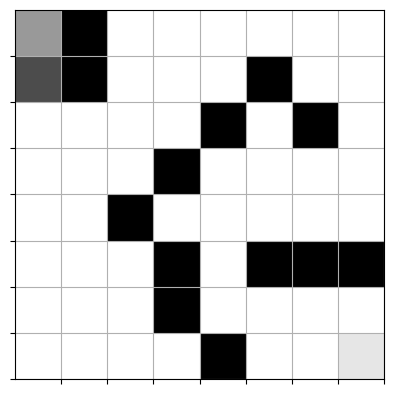

In [6]:
qmaze = TreasureMaze(maze)
canvas, reward, game_over = qmaze.act(DOWN)
print("reward=", reward)
show(qmaze)

<div class="alert alert-block alert-warning" style="color:black;">
    <b>NOTE:</b> This <b>play_game()</b> function simulates a full game based on the provided trained model. The other parameters include the TreasureMaze object, the starting position of the pirate and max amount of steps to make sure the code does not get stuck in a loop.
</div>

In [7]:
def play_game(model, qmaze, pirate_cell, max_steps=None):
    qmaze.reset(pirate_cell)
    envstate = qmaze.observe()
    steps = 0
    if max_steps is None:
        max_steps = qmaze.maze.size * 4  # safety cutoff

    while steps < max_steps:
        state = np.asarray(envstate, dtype=np.float32)
        if state.ndim == 1:
            state = np.expand_dims(state, axis=0)

        q_values = model(state, training=False).numpy()
        action = np.argmax(q_values[0])

        envstate, reward, game_status = qmaze.act(action)
        steps += 1

        if game_status == 'win':
            return True
        elif game_status == 'lose':
            return False

    return False  # timed out with no result

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b>
    This <b>completion_check()</b> function helps you to determine whether the pirate can win any game at all. If your maze is not well designed, the pirate may not win any game at all. In this case, your training would not yield any result. The provided maze in this notebook ensures that there is a path to win and you can run this method to check.
</div>

In [8]:
def completion_check(model, maze_or_qmaze, max_steps=None):
    """Require a greedy win from EVERY non-target free starting cell."""
    qmaze = (maze_or_qmaze if isinstance(maze_or_qmaze, TreasureMaze)
             else TreasureMaze(maze_or_qmaze))
    for cell in qmaze.free_cells:
        # A blocked start must fail instead of being silently skipped.
        if not qmaze.valid_actions(cell):
            return False
        if not play_game(model, qmaze, cell, max_steps=max_steps):
            return False
    return True


<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b>
</b>The <b>build_model()</b> function in the block below will build the neural network model. Review the code and note the number of layers, as well as the activation, optimizer, and loss functions that are used to train the model.
</div>

In [9]:
def build_model(maze):
    model = Sequential()
    model.add(Dense(maze.size, input_shape=(maze.size,)))
    model.add(PReLU())
    model.add(Dense(maze.size))
    model.add(PReLU())
    model.add(Dense(num_actions))
    model.compile(optimizer='adam', loss='mse')
    return model

<div class="alert alert-block alert-warning" style="color:black;">
    <b>Note:</b>
    This <b>train_step()</b> helper function in the block below is used to help predict Q-values (quality values) in the current modelto see how good each action is in a given state and improve the Q-network by reducing the gap between what is predicted and what should have been predicted. 
</div>
<br>
<div class="alert alert-block alert-info" style="color:black;">
If you're interested in reading up on the <i>@tf.function</i>, which is a decorator for Tensorflow to run this code into a TensorFlow computation graph, please refer to this link: <a href="https://www.tensorflow.org/guide/intro_to_graphs">https://www.tensorflow.org/guide/intro_to_graphs</a>
</div>


<h2>Tensorflow GPU Warning</h2>
<div class="alert alert-block alert-danger" style="color: #333333;">
    You will see a <b>warning in red</b> "INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.". This is simply coming from <b>Tensorflow skipping using GPU for this assignment.</b>  
</div>

In [10]:
def make_train_step(model, learning_rate=0.001):
    """Bind each TensorFlow update graph to its own model and optimizer."""
    optimizer = Adam(learning_rate=learning_rate)
    loss_fn = tf.keras.losses.MeanSquaredError()

    @tf.function(reduce_retracing=True)
    def train_step(x, y):
        with tf.GradientTape() as tape:
            predicted_q = model(x, training=True)
            loss = loss_fn(y, predicted_q)
        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))
        return loss

    return train_step


In [11]:
def format_time(seconds):
    if seconds < 400:
        s = float(seconds)
        return "%.1f seconds" % (s,)
    elif seconds < 4000:
        m = seconds / 60.0
        return "%.2f minutes" % (m,)
    else:
        h = seconds / 3600.0
        return "%.2f hours" % (h,)

# #TODO: Complete the Q-Training Algorithm Code Block

<div class="alert alert-block alert-info" style="color:black;">
    This is your deep Q-learning implementation. The goal of your deep Q-learning implementation is to find the best possible navigation sequence that results in reaching the treasure cell while maximizing the reward. In your implementation, you need to determine the optimal number of epochs to achieve a 100% win rate.
</div>
    <b>Pseudocode:</b>
    <br>
    For each epoch:
        Reset the environment at a random starting cell
        agent_cell = randomly select a free cell
        <br>
        <b>Hint:</b> Review the reset method in the TreasureMaze.py class.
    
        Set the initial environment state
        env_state should reference the environment's current state
        Hint: Review the observe method in the TreasureMaze.py class.

        While game status is not game over:
           previous_envstate = env_state
            Decide on an action:
                - If possible, take a random valid exploration action and 
                  randomly choose action (left, right, up, down)
                  and assign it to an action variable
                - Else, pick the best exploitation action from the model and assign it to an action variable
                  Hint: Review the predict method in the GameExperience.py class.
    
           Retrieve the values below from the act() method.
           env_state, reward, game_status = qmaze.act(action)
           Hint: Review the act method in the TreasureMaze.py class.
    
            Track the wins and losses from the game_status using win_history 
         
           Store the episode below in the Experience replay object
           episode = [previous_envstate, action, reward, envstate, game_status]
           Hint: Review the remember method in the GameExperience.py class.
        
           Train neural network model and evaluate loss
           Hint: Call GameExperience.get_data to retrieve training data (input and target) 
           and pass to the train_step method and assign it to batch_loss and append to the loss variable
        
      If the win rate is above the threshold and your model passes the completion check, that would be your epoch.

Note: A 100% win rate <b>DOES NOT EXPLICITLY MEAN</b> that you have solved the maze. It simply indicates that during the last evaluation, the pirate <i>happened</i> to get to the treasure. Be sure to utilise the <b>completion_check()</b> function to validate your pirate found the treasure at every starting point and consistently! 

<b> You will need to complete the section starting with #START_HERE. Please use the pseudocode above as guidance. </b>


In [12]:
def qtrain(model, maze, **opt):
    """Train DQN with the supplied environment and replay classes unchanged.

    One outer epoch is one game from a randomly selected free cell.
    Stop at the first observed 32-game perfect window that ALSO passes
    greedy evaluation from every free starting cell. This is not proof
    of a globally optimal epoch count or shortest paths.
    """
    global epsilon
    n_epoch = int(opt.get('n_epoch', 3000))
    max_memory = int(opt.get('max_memory', 8 * maze.size))
    data_size = int(opt.get('data_size', 32))
    target_update_freq = int(opt.get('target_update_freq', 50))
    discount = float(opt.get('discount', 0.95))
    learning_rate = float(opt.get('learning_rate', 0.001))
    decay = float(opt.get('epsilon_decay', 0.995))
    minimum = float(opt.get('epsilon_min', 0.05))
    epsilon = float(opt.get('epsilon_start', 1.0))
    max_steps = int(opt.get('max_steps', 4 * maze.size))
    seed = int(opt.get('seed', 42))
    if min(n_epoch, max_memory, data_size, target_update_freq, max_steps) < 1:
        raise ValueError('Epoch, memory, batch, update, and step limits must be positive.')
    if not (0 <= minimum <= epsilon <= 1 and 0 < decay <= 1 and 0 <= discount <= 1):
        raise ValueError('Invalid epsilon schedule or discount.')

    # Reproducible sampling for this run; initialization is seeded before build_model.
    random.seed(seed)
    np.random.seed(seed)
    start_time = time.perf_counter()
    qmaze = TreasureMaze(maze)
    target_model = clone_model(model)
    target_model.set_weights(model.get_weights())
    experience = GameExperience(model, target_model,
                                max_memory=max_memory, discount=discount)
    # A fresh optimizer/graph is bound to this model, including on a rerun.
    train_step = make_train_step(model, learning_rate)
    win_history, records = [], []
    hsize = maze.size // 2
    total_steps = 0
    first_verified_epoch = None

    for epoch in range(n_epoch):
        qmaze.reset(random.choice(qmaze.free_cells))
        env_state = qmaze.observe()
        losses = []
        epsilon_used = epsilon
        status = 'not_over'

        for step in range(1, max_steps + 1):
            previous_state = env_state
            valid_actions = qmaze.valid_actions()
            if not valid_actions:
                status = 'lose'
                break
            if np.random.random() < epsilon_used:
                # Exploration samples a physically valid move.
                action = int(random.choice(valid_actions))
            else:
                # Unmasked argmax matches the supplied play_game evaluation.
                # Invalid greedy choices receive environment feedback too.
                action = int(np.argmax(experience.predict(previous_state)))

            env_state, reward, status = qmaze.act(action)
            # CRITICAL: get_data() checks `if done`. Nonempty strings such as
            # 'not_over' are truthy and would incorrectly suppress bootstrapping.
            # The explicit cutoff is treated as a terminal failure for this task.
            timeout = step == max_steps and status == 'not_over'
            done = status in ('win', 'lose') or timeout
            experience.remember([previous_state, action, float(reward),
                                 env_state, bool(done)])
            total_steps += 1
            inputs, targets = experience.get_data(data_size)
            batch_loss = float(train_step(inputs, targets).numpy())
            if not np.isfinite(batch_loss):
                raise FloatingPointError('Training produced a non-finite loss.')
            losses.append(batch_loss)
            if done:
                if timeout:
                    status = 'timeout'
                break

        win_history.append(int(status == 'win'))
        win_rate = float(np.mean(win_history[-hsize:]))
        # Freeze the target between periodic hard synchronization events.
        if (epoch + 1) % target_update_freq == 0:
            target_model.set_weights(model.get_weights())
        row = dict(epoch=epoch, games=epoch + 1, steps=step,
                   mean_loss=float(np.mean(losses)) if losses else 0.0,
                   reward=float(qmaze.total_reward), status=status,
                   win_rate=win_rate, epsilon=epsilon_used,
                   transitions=total_steps)
        records.append(row)
        # Save live evidence without waiting for the notebook cell to finish.
        if (epoch + 1) % 25 == 0:
            with open('training_progress.json', 'w') as file:
                json.dump(row, file, indent=2)
        if epoch == 0 or (epoch + 1) % 25 == 0:
            print(f"Epoch {epoch:4d} | loss={row['mean_loss']:.5f} | "
                  f"steps={step:3d} | reward={row['reward']:6.2f} | "
                  f"win{hsize}={win_rate:.3f} | epsilon={epsilon_used:.3f}")
        # A full window is required; 1/1 success is not 100% completion.
        if (len(win_history) >= hsize and sum(win_history[-hsize:]) == hsize
                and completion_check(model, TreasureMaze(maze), max_steps=max_steps)):
            first_verified_epoch = epoch
            print(f'First verified stopping epoch: {epoch} ({epoch + 1} games).')
            break
        epsilon = max(minimum, epsilon_used * decay)

    results = dict(records=records, first_verified_epoch=first_verified_epoch,
                   seconds=time.perf_counter() - start_time,
                   settings=dict(seed=seed, learning_rate=learning_rate,
                                 discount=discount, epsilon_start=opt.get('epsilon_start', 1.0),
                                 epsilon_decay=decay, epsilon_min=minimum,
                                 max_memory=max_memory, data_size=data_size,
                                 target_update_freq=target_update_freq,
                                 max_steps=max_steps, n_epoch=n_epoch))
    with open('training_results.json', 'w') as file:
        json.dump(results, file, indent=2)
    if first_verified_epoch is None:
        print('Budget exhausted: no verified stopping epoch. Inspect evaluation before claiming success.')
    return results


## Test Your Model

Now we will start testing the deep Q-learning implementation. To begin, select **Cell**, then **Run All** from the menu bar. This will run your notebook. As it runs, you should see output begin to appear beneath the next few cells. The code below creates an <b>instance</b> of TreasureMaze. This does not show your actual training done.

Out[13]: <matplotlib.image.AxesImage at 0x117de9f90>


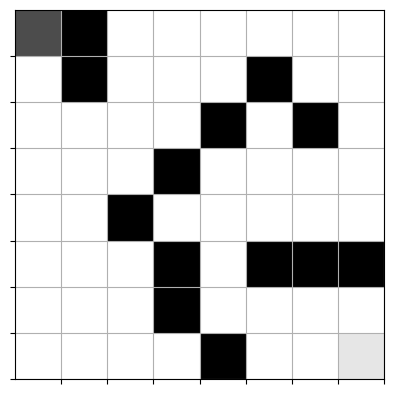

In [13]:
qmaze = TreasureMaze(maze)
show(qmaze)

In the next code block, you will build your model using the <b>build_model</b> function and train it using deep Q-learning. Note: This step takes several minutes to fully run.



<div class="alert alert-block alert-danger" style="color: #333333;">
  <b>WARNING</b>  If you did not attempt the assignment, the code <b>will</b> error out at this section.
 </div>

In [14]:
# Set the seed BEFORE constructing the network so initialization is controlled.
SEED = 42
tf.keras.utils.set_random_seed(SEED)
model = build_model(maze)
model.summary()
training = qtrain(model, maze, n_epoch=3000, max_memory=8 * maze.size,
                  data_size=32, target_update_freq=50, discount=0.95,
                  learning_rate=0.001, epsilon_start=1.0,
                  epsilon_decay=0.995, epsilon_min=0.05, seed=SEED)
model.save('Chimunya_Russell_ProjectTwo.keras')


Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu (PReLU)                 │ (None, 64)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu_1 (PReLU)               │ (None, 64)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴─────────────────────

[local project folder]/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b> This cell will check to see if the model passes the completion check. Note: This could take several minutes.
</div>

All-start greedy completion: True


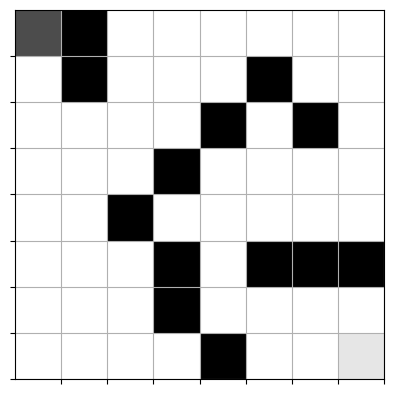

In [15]:
# Print the Boolean result explicitly; a maze picture alone is not evidence.
all_starts_pass = completion_check(model, TreasureMaze(maze))
print('All-start greedy completion:', all_starts_pass)
assert all_starts_pass, 'Not solved from every free start; do not claim completion.'
show(qmaze)
plt.show()


This cell will test your model for one game. It will start the pirate at the top-left corner and run <b>play_game()</b>. The agent should find a path from the starting position to the target (treasure). The treasure is located in the bottom-right corner.

Top-left greedy game: True
Final position: (7, 7) | treasure: (7, 7)
Game reward: -2.220446049250313e-16


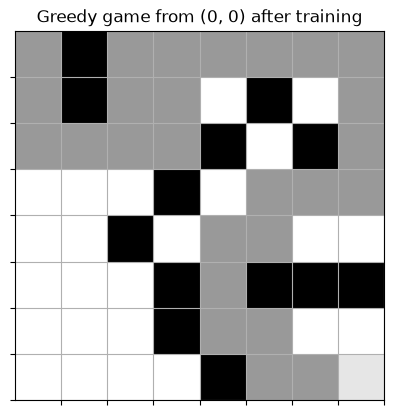

In [16]:
pirate_start = (0, 0)
qmaze = TreasureMaze(maze)
top_left_pass = play_game(model, qmaze, pirate_start)
print('Top-left greedy game:', top_left_pass)
print('Final position:', qmaze.state[:2], '| treasure:', qmaze.target)
print('Game reward:', qmaze.total_reward)
assert top_left_pass and qmaze.state[:2] == qmaze.target
show(qmaze)
plt.title('Greedy game from (0, 0) after training')
plt.show()


## Verify targets and measure paths
The replay interface test below checks both continuing and terminal targets. Breadth-first search is used only as an independent shortest-path benchmark; it never supplies training actions, replay data, or network targets.

In [17]:
# Verify the supplied replay helper gets the correct target in both cases.
probe = clone_model(model)
probe.set_weights([np.zeros_like(w) for w in model.get_weights()])
probe_target = clone_model(model)
weights = [np.zeros_like(w) for w in model.get_weights()]
weights[-1] = np.ones_like(weights[-1]) * 2.0
probe_target.set_weights(weights)
state = TreasureMaze(maze).observe()
for done, expected in [(False, -0.04 + 0.95 * 2.0), (True, -0.04)]:
    replay = GameExperience(probe, probe_target, max_memory=1, discount=0.95)
    replay.remember([state, 0, -0.04, state, done])
    inputs, targets = replay.get_data(1)
    assert np.isclose(targets[0, 0], expected)
print('PASS: continuing target = 1.86; terminal target = -0.04.')


PASS: continuing target = 1.86; terminal target = -0.04.


In [18]:
from collections import deque

def shortest_distance(start):
    queue = deque([(start, 0)])
    seen = {start}
    while queue:
        (r, c), distance = queue.popleft()
        if (r, c) == (7, 7):
            return distance
        for dr, dc in [(0, -1), (-1, 0), (0, 1), (1, 0)]:
            nxt = (r + dr, c + dc)
            if (0 <= nxt[0] < 8 and 0 <= nxt[1] < 8
                    and maze[nxt] == 1 and nxt not in seen):
                seen.add(nxt)
                queue.append((nxt, distance + 1))
    return None

def greedy_path(start):
    game = TreasureMaze(maze)
    game.reset(start)
    path = [start]
    for _ in range(4 * maze.size):
        values = model(np.asarray(game.observe(), dtype=np.float32), training=False).numpy()[0]
        _, _, status = game.act(int(np.argmax(values)))
        path.append(tuple(game.state[:2]))
        if status in ('win', 'lose'):
            return status, path, float(game.total_reward)
    return 'timeout', path, float(game.total_reward)

evaluation = []
for start in TreasureMaze(maze).free_cells:
    status, path, reward = greedy_path(start)
    optimal = shortest_distance(start)
    evaluation.append(dict(start=list(start), status=status, steps=len(path)-1,
                           shortest=optimal, reward=reward,
                           shortest_path=(status == 'win' and len(path)-1 == optimal)))
status, top_path, top_reward = greedy_path((0, 0))
summary = dict(starts=len(evaluation), wins=sum(r['status']=='win' for r in evaluation),
               shortest_paths=sum(r['shortest_path'] for r in evaluation),
               top_left_steps=len(top_path)-1, top_left_shortest=shortest_distance((0, 0)),
               top_left_reward=top_reward, top_left_path=top_path,
               first_verified_epoch=training['first_verified_epoch'],
               games=len(training['records']))
print(json.dumps(summary, indent=2))
assert summary['wins'] == summary['starts']
with open('evaluation_results.json', 'w') as file:
    json.dump(dict(summary=summary, all_starts=evaluation), file, indent=2)
with open('training_history.csv', 'w', newline='') as file:
    writer = csv.DictWriter(file, fieldnames=training['records'][0].keys())
    writer.writeheader()
    writer.writerows(training['records'])


{
  "starts": 50,
  "wins": 50,
  "shortest_paths": 28,
  "top_left_steps": 26,
  "top_left_shortest": 24,
  "top_left_reward": -2.220446049250313e-16,
  "top_left_path": [
    [
      0,
      0
    ],
    [
      1,
      0
    ],
    [
      2,
      0
    ],
    [
      2,
      1
    ],
    [
      2,
      2
    ],
    [
      2,
      3
    ],
    [
      1,
      3
    ],
    [
      1,
      2
    ],
    [
      0,
      2
    ],
    [
      0,
      3
    ],
    [
      0,
      4
    ],
    [
      0,
      5
    ],
    [
      0,
      6
    ],
    [
      0,
      7
    ],
    [
      1,
      7
    ],
    [
      2,
      7
    ],
    [
      3,
      7
    ],
    [
      3,
      6
    ],
    [
      3,
      5
    ],
    [
      4,
      5
    ],
    [
      4,
      4
    ],
    [
      5,
      4
    ],
    [
      6,
      4
    ],
    [
      6,
      5
    ],
    [
      7,
      5
    ],
    [
      7,
      6
    ],
    [
      7,
      7
    ]
  ],
  "first_veri

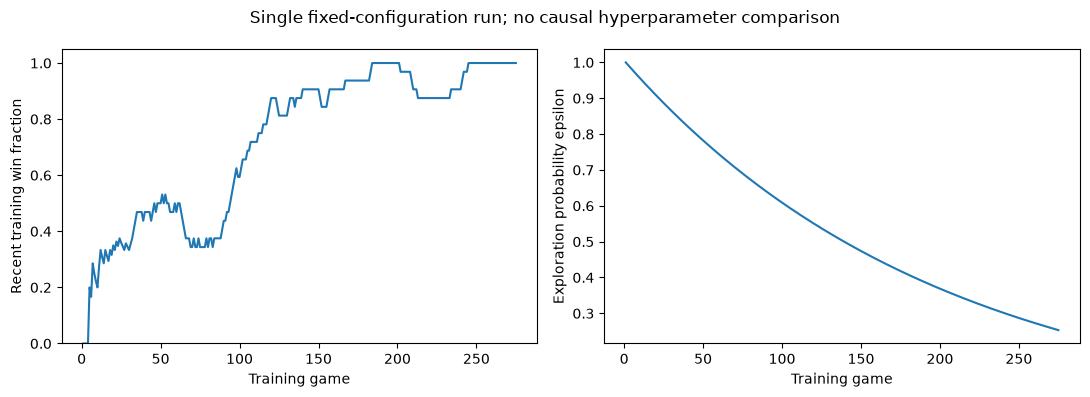

In [19]:
records = training['records']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot([r['games'] for r in records], [r['win_rate'] for r in records])
axes[0].set(xlabel='Training game', ylabel='Recent training win fraction', ylim=(0, 1.05))
axes[1].plot([r['games'] for r in records], [r['epsilon'] for r in records])
axes[1].set(xlabel='Training game', ylabel='Exploration probability epsilon')
fig.suptitle('Single fixed-configuration run; no causal hyperparameter comparison')
plt.tight_layout()
plt.savefig('training_summary.png', dpi=160)
plt.show()


## Measured results of this execution

The seed-42 run passed the stopping criterion at zero-based epoch **274**, after **275 training games**. The frozen greedy policy reached the treasure from **50/50** free starts. Its top-left route used **26 moves**, compared with the independent BFS minimum of **24**. Only **28/50** routes matched shortest-path distances. Completion is verified, but universal shortest-path optimality is not claimed.

The last training epsilon was **0.253**; evaluation used no random exploration. A high training epsilon does not invalidate a separate greedy completion check. The maximum budget was 3000 games; training stopped early on verified task outcomes rather than an arbitrary 80-game limit.


## Interpretation and experimental controls
A short exploratory run cannot isolate a learning-rate effect if gamma changes too. This notebook uses one stated configuration and reports verified task outcomes; it makes no causal claim about either hyperparameter. For a controlled follow-up, change only learning rate while holding gamma, architecture, replay size, epsilon schedule, and game budget fixed. Repeat matched seeds, evaluate greedily, and compare win fractions, path lengths, and returns. Test gamma separately. A fixed budget must be long enough to observe learning beyond early high exploration.

With epsilon = max(0.05, 0.995**epoch), epoch 80 still has approximately 0.670 exploration probability. The schedule reaches its 0.05 floor at approximately epoch 598. Early stopping here requires both 32 consecutive training wins and every-start greedy completion, rather than merely ending at 80 games. The observed stopping epoch is not a globally optimal epoch count.

### Scope and environment limitations
The `.py` files are unchanged. Their actual behavior governs this run: revisits cost -0.25, successful moves cost -0.04, and the treasure pays +1. The specification's separate -0.8 boundary penalty is not implemented in this helper. Its invalid-action branch also retains the prior mode, so the nominal -0.75 penalty is not reliably applied. The notebook does not silently patch this discrepancy. Observations omit visited history even though rewards depend on it, so the observation is not a complete Markov state. Passing this fixed maze does not establish generalization, shortest paths, or victory over a modeled human opponent.

### References
Mnih, V., Kavukcuoglu, K., Silver, D., Graves, A., Antonoglou, I., Wierstra, D., & Riedmiller, M. (2013). *Playing Atari with deep reinforcement learning*. https://arxiv.org/abs/1312.5602

Sutton, R. S., & Barto, A. G. (2018). *Reinforcement learning: An introduction* (2nd ed.). MIT Press.

TensorFlow. (n.d.). *Train a deep Q network with TF-Agents*. https://www.tensorflow.org/agents/tutorials/1_dqn_tutorial


## Save and Submit Your Work

<div class="alert alert-block alert-info" style="color:black;">
    <b>Hint:</b> To use the markdown block below, double click in the <b>Type Markdown and LaTeX:  𝛼2</b> block below, to turn it back to html, Run the cell.
</div>

After you have finished creating the code for your notebook, save your work.
Make sure that your notebook contains your name in the filename (e.g. Doe_Jane_ProjectTwo.html). Download this file as an .html file clicking on ***file*** in *Jupyter Notebook*, navigating down to ***Download as*** and clicking on ***.html***. 
Download a copy of your .html file and submit it to Brightspace.